<a href="https://colab.research.google.com/github/miriamamin1213-ux/FinalModels/blob/main/GPT2LLMHecktorLR2e-5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 43.4MB/s]


Patients: 588 
Class distribution:
 HPV Status
0     58
1    530
Name: count, dtype: int64
Class weights: tensor([5.1087, 0.5542], device='cuda:0')


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 hidden size: 768 Layers: 12 Heads: 12
Epoch 50/500 | Train Loss=0.0475 | Test Loss=0.6137 | BA=0.5723 | AUC=0.7288
Epoch 100/500 | Train Loss=0.0015 | Test Loss=1.3792 | BA=0.5825 | AUC=0.7303
Epoch 150/500 | Train Loss=0.0000 | Test Loss=2.2306 | BA=0.5825 | AUC=0.7288
Epoch 200/500 | Train Loss=0.0053 | Test Loss=1.2140 | BA=0.6706 | AUC=0.7319
Epoch 250/500 | Train Loss=0.0001 | Test Loss=2.0831 | BA=0.6753 | AUC=0.7193
Epoch 300/500 | Train Loss=0.0005 | Test Loss=1.6178 | BA=0.6706 | AUC=0.7759
Epoch 350/500 | Train Loss=0.0379 | Test Loss=0.7392 | BA=0.6887 | AUC=0.7736
Epoch 400/500 | Train Loss=0.0001 | Test Loss=1.7177 | BA=0.6431 | AUC=0.7783
Epoch 450/500 | Train Loss=0.0025 | Test Loss=0.8878 | BA=0.7075 | AUC=0.7956
Epoch 500/500 | Train Loss=0.0000 | Test Loss=1.8966 | BA=0.5920 | AUC=0.7964

===== Best Test Loss =====
              precision    recall  f1-score   support

HPV Negative     0.1875    0.7500    0.3000        12
HPV Positive     0.9571    0.6321    0.7

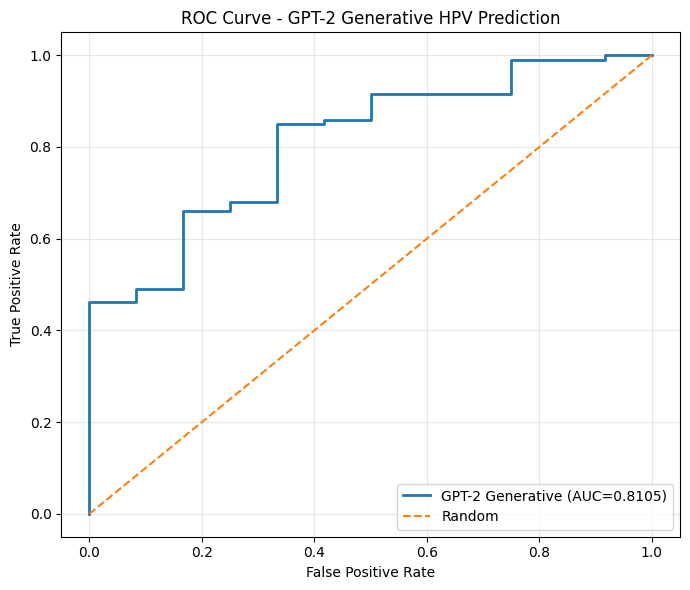


===== GENERATED TEST LABELS =====
Patient 1: 'HPV Positive' -> 1
Patient 2: 'HPV Positive' -> 1
Patient 3: 'HPV Positive' -> 1
Patient 4: 'HPV Positive' -> 1
Patient 5: 'HPV Positive' -> 1
Patient 6: 'HPV Positive' -> 1
Patient 7: 'HPV Negative' -> 0
Patient 8: 'HPV Positive' -> 1
Patient 9: 'HPV Positive' -> 1
Patient 10: 'HPV Negative' -> 0
Patient 11: 'HPV Positive' -> 1
Patient 12: 'HPV Positive' -> 1
Patient 13: 'HPV Positive' -> 1
Patient 14: 'HPV Positive' -> 1
Patient 15: 'HPV Positive' -> 1
Patient 16: 'HPV Positive' -> 1
Patient 17: 'HPV Positive' -> 1
Patient 18: 'HPV Positive' -> 1
Patient 19: 'HPV Positive' -> 1
Patient 20: 'HPV Positive' -> 1
Patient 21: 'HPV Positive' -> 1
Patient 22: 'HPV Positive' -> 1
Patient 23: 'HPV Positive' -> 1
Patient 24: 'HPV Positive' -> 1
Patient 25: 'HPV Positive' -> 1
Patient 26: 'HPV Positive' -> 1
Patient 27: 'HPV Positive' -> 1
Patient 28: 'HPV Positive' -> 1
Patient 29: 'HPV Positive' -> 1
Patient 30: 'HPV Positive' -> 1
Patient 31: 'H

In [1]:

# ============================================================
# GPT-2 GENERATIVE HPV PREDICTION - HECKTOR
# ============================================================

import os, random, numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, balanced_accuracy_score, f1_score, roc_auc_score, roc_curve
import gdown


# 1. Reproducibility

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


# 2. Load HECKTOR data

if not os.path.exists("HPV2025.xlsx"):
    try:
        path = gdown.download(
            id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
            output="HPV2025.xlsx",
            quiet=False,
            fuzzy=True
        )
    except Exception as e:
        print("Google Drive download failed:", e)
        path = None

    if path is None or not os.path.exists("HPV2025.xlsx"):
        from google.colab import files
        uploaded = files.upload()
        if "HPV2025.xlsx" not in uploaded:
            raise FileNotFoundError("Please upload the file named HPV2025.xlsx")

df = pd.read_excel("HPV2025.xlsx")
df = df.dropna(subset=["HPV Status"]).copy()
df = df.drop(columns=["PatientID", "CenterID", "Task 1", "Task 2", "Task 3"], errors="ignore")


def stage_num(x):
    if isinstance(x, str) and x.strip().upper().startswith(("T", "N", "M")):
        try:
            return int(x.strip().upper()[1:])
        except:
            return np.nan
    return x


for c in ["T-stage", "N-stage", "M-stage"]:
    df[c] = df[c].apply(stage_num)


features = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "Relapse", "RFS", "Treatment",
    "T-stage", "N-stage", "M-stage"
]

X = df[features].copy()
y = df["HPV Status"].astype(int).copy()

print("Patients:", len(df), "\nClass distribution:\n", y.value_counts().sort_index())


# 3. Stratified split and train-only imputation

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

cat_cols = [
    "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "Relapse", "Treatment",
    "T-stage", "N-stage", "M-stage"
]
num_cols = ["Age", "RFS"]

for c in num_cols:
    median = X_train[c].median()
    X_train[c] = X_train[c].fillna(median)
    X_test[c] = X_test[c].fillna(median)

for c in cat_cols:
    mode = X_train[c].mode()[0]
    X_train[c] = X_train[c].fillna(mode)
    X_test[c] = X_test[c].fillna(mode)


# 4. Automatic class weights from training data only

class_counts = np.bincount(y_train.to_numpy())

class_weights = torch.tensor(
    len(y_train) / (len(class_counts) * class_counts),
    dtype=torch.float32,
    device=device
)

print("Class weights:", class_weights)


# 5. Clinical narratives and text targets

def patient_to_text(row):
    gender = "male" if int(row["Gender"]) == 1 else "female"
    smoker = "current smoker" if int(row["Tobacco Consumption"]) == 1 else "non-smoker"
    alcohol = "consumes alcohol" if int(row["Alcohol Consumption"]) == 1 else "does not consume alcohol"
    relapse = "has experienced disease relapse" if int(row["Relapse"]) == 1 else "has not experienced disease relapse"

    return (
        f"You are a clinician specialising in head and neck cancer. "
        f"Your task is to predict the patient's Human Papillomavirus (HPV) status. "
        f"The patient was diagnosed at {row['Age']:.0f} years of age and is {gender}. "
        f"The patient is a {smoker} and {alcohol}. "
        f"Performance status is {row['Performance Status']}. "
        f"The patient {relapse}. "
        f"Relapse-free survival is {row['RFS']} days. "
        f"Treatment type is {row['Treatment']}. "
        f"The tumour stage is T{int(row['T-stage'])}. "
        f"The nodal stage is N{int(row['N-stage'])}. "
        f"The metastatic stage is M{int(row['M-stage'])}. "
        f"Based on the information provided, predict the patient's HPV status. "
        f"Respond with exactly one label: HPV Positive or HPV Negative."
    )


train_texts = [patient_to_text(r) for _, r in X_train.iterrows()]
test_texts = [patient_to_text(r) for _, r in X_test.iterrows()]

train_targets = ["HPV Positive" if v == 1 else "HPV Negative" for v in y_train]
test_targets = ["HPV Positive" if v == 1 else "HPV Negative" for v in y_test]


# 6. GPT-2 tokenizer

MODEL_NAME = "openai-community/gpt2"

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

MAX_LENGTH = 256


# 7. Generative dataset: loss is applied to target tokens, not prompt

class GPT2GenerationDataset(Dataset):
    def __init__(self, texts, targets, class_labels, tokenizer, max_length=256):
        self.items = []

        for text, target, label in zip(texts, targets, class_labels):
            prompt_ids = tokenizer.encode(text, add_special_tokens=False)
            target_ids = tokenizer.encode(" " + target, add_special_tokens=False) + [
                tokenizer.eos_token_id
            ]

            prompt_ids = prompt_ids[:max_length - len(target_ids)]
            ids = prompt_ids + target_ids
            labels = [-100] * len(prompt_ids) + target_ids
            pad = max_length - len(ids)

            self.items.append((
                ids + [tokenizer.pad_token_id] * pad,
                [1] * len(ids) + [0] * pad,
                labels + [-100] * pad,
                int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, labels, label = self.items[i]

        return {
            "input_ids": torch.tensor(ids),
            "attention_mask": torch.tensor(mask),
            "labels": torch.tensor(labels),
            "class_label": torch.tensor(label, dtype=torch.long)
        }


train_dataset = GPT2GenerationDataset(
    train_texts, train_targets, y_train.to_numpy(), tokenizer, MAX_LENGTH
)
test_dataset = GPT2GenerationDataset(
    test_texts, test_targets, y_test.to_numpy(), tokenizer, MAX_LENGTH
)

BATCH_SIZE = 8

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


# 8. GPT-2 generative language model

model = GPT2LMHeadModel.from_pretrained(MODEL_NAME).to(device)
model.config.pad_token_id = tokenizer.pad_token_id

print(
    "GPT-2 hidden size:", model.config.n_embd,
    "Layers:", model.config.n_layer,
    "Heads:", model.config.n_head
)


# 9. Optimizer
# ONLY CHANGE: learning rate reduced from 1e-3 to 2e-5

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5,
    weight_decay=1e-4
)


# 10. Class-weighted generation loss

def weighted_generation_loss(logits, labels, class_labels):
    shift_logits = logits[:, :-1, :].contiguous()
    shift_labels = labels[:, 1:].contiguous()

    token_loss = nn.CrossEntropyLoss(reduction="none")(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_labels.reshape(-1)
    ).view(shift_labels.size(0), -1)

    valid = (shift_labels != -100).float()
    example_loss = (token_loss * valid).sum(1) / valid.sum(1).clamp(min=1)

    return (example_loss * class_weights[class_labels]).mean()


# 11. Compare conditional likelihood of both labels for continuous ROC scores

def get_hpv_scores(prompts, batch_size=8):
    model.eval()
    scores = []

    with torch.no_grad():
        for start in range(0, len(prompts), batch_size):
            for prompt in prompts[start:start + batch_size]:
                prompt_ids = tokenizer.encode(
                    prompt, add_special_tokens=False
                )[:MAX_LENGTH - 6]

                candidate_losses = []

                for candidate in ["HPV Positive", "HPV Negative"]:
                    target_ids = tokenizer.encode(
                        " " + candidate, add_special_tokens=False
                    )

                    ids = prompt_ids + target_ids
                    inputs = torch.tensor([ids], device=device)

                    outputs = model(
                        input_ids=inputs,
                        attention_mask=torch.ones_like(inputs)
                    )

                    logits = outputs.logits[
                        0,
                        len(prompt_ids) - 1:len(prompt_ids) + len(target_ids) - 1,
                        :
                    ]

                    targets = inputs[
                        0,
                        len(prompt_ids):len(prompt_ids) + len(target_ids)
                    ]

                    loss = nn.functional.cross_entropy(
                        logits, targets, reduction="mean"
                    )

                    candidate_losses.append(loss.item())

                scores.append(candidate_losses[1] - candidate_losses[0])

    return np.asarray(scores)


# 12. Training

EPOCHS = 500

best_test_loss = float("inf")
best_test_ba = -1
best_test_auc = -1

best_loss_path = "best_model_gpt2_generation_loss.pth"
best_ba_path = "best_model_gpt2_generation_ba.pth"
best_auc_path = "best_model_gpt2_generation_auc.pth"


for epoch in range(EPOCHS):
    model.train()
    train_loss = 0

    for batch in train_loader:
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        classes = batch["class_label"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(input_ids=ids, attention_mask=mask)
        loss = weighted_generation_loss(outputs.logits, labels, classes)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    model.eval()
    test_loss = 0

    with torch.no_grad():
        for batch in test_loader:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            classes = batch["class_label"].to(device)

            outputs = model(input_ids=ids, attention_mask=mask)
            test_loss += weighted_generation_loss(
                outputs.logits, labels, classes
            ).item()

    avg_test_loss = test_loss / len(test_loader)

    scores = get_hpv_scores(test_texts, BATCH_SIZE)
    predictions = (scores > 0).astype(int)

    ba = balanced_accuracy_score(y_test, predictions)
    auc = roc_auc_score(y_test, scores)

    if avg_test_loss < best_test_loss:
        best_test_loss = avg_test_loss
        torch.save(model.state_dict(), best_loss_path)

    if ba > best_test_ba:
        best_test_ba = ba
        torch.save(model.state_dict(), best_ba_path)

    if auc > best_test_auc:
        best_test_auc = auc
        torch.save(model.state_dict(), best_auc_path)

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss={avg_train_loss:.4f} | "
            f"Test Loss={avg_test_loss:.4f} | "
            f"BA={ba:.4f} | AUC={auc:.4f}"
        )


# 13. Evaluation and save ROC results

ROC_DIR = Path("ROC_HECKTOR_GPT2")
ROC_DIR.mkdir(parents=True, exist_ok=True)


def evaluate_checkpoint(path, name):
    model.load_state_dict(torch.load(path, map_location=device))

    scores = get_hpv_scores(test_texts, BATCH_SIZE)
    pred = (scores > 0).astype(int)

    ba = balanced_accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, zero_division=0)
    auc = roc_auc_score(y_test, scores)

    print(f"\n===== {name} =====")
    print(classification_report(
        y_test,
        pred,
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))
    print(f"Balanced Accuracy: {ba:.4f}\nF1: {f1:.4f}\nROC-AUC: {auc:.4f}")

    return scores, pred, ba, f1, auc


loss_scores, loss_pred, loss_ba, loss_f1, loss_auc = evaluate_checkpoint(
    best_loss_path, "Best Test Loss"
)
ba_scores, ba_pred, ba_value, ba_f1, ba_auc = evaluate_checkpoint(
    best_ba_path, "Best Balanced Accuracy"
)
auc_scores, auc_pred, auc_ba, auc_f1, auc_value = evaluate_checkpoint(
    best_auc_path, "Best ROC-AUC"
)


# Save best-AUC ROC coordinates, per-patient scores, and plot

fpr, tpr, thresholds = roc_curve(y_test, auc_scores)

pd.DataFrame({
    "FPR": fpr,
    "TPR": tpr,
    "Threshold": thresholds
}).to_csv(ROC_DIR / "roc_coordinates_best_auc.csv", index=False)

pd.DataFrame({
    "True_Label": y_test.to_numpy(),
    "HPV_Positive_Score": auc_scores,
    "Predicted_Label": auc_pred
}).to_csv(ROC_DIR / "roc_patient_scores_best_auc.csv", index=False)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f"GPT-2 Generative (AUC={auc_value:.4f})")
plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - GPT-2 Generative HPV Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ROC_DIR / "roc_curve_best_auc.png", dpi=300, bbox_inches="tight")
plt.show()


# Save summary

pd.DataFrame([
    {"Checkpoint": "Best Loss", "BA": loss_ba, "F1": loss_f1, "AUC": loss_auc},
    {"Checkpoint": "Best BA", "BA": ba_value, "F1": ba_f1, "AUC": ba_auc},
    {"Checkpoint": "Best AUC", "BA": auc_ba, "F1": auc_f1, "AUC": auc_value}
]).to_csv(ROC_DIR / "evaluation_summary.csv", index=False)


# 14. Actual generated labels - only exact outputs accepted

def generate_prediction(prompt):
    model.eval()

    enc = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    ).to(device)

    with torch.no_grad():
        generated = model.generate(
            **enc,
            max_new_tokens=5,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    new_tokens = generated[0, enc["input_ids"].shape[1]:]

    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


def extract_hpv_label(text):
    text = " ".join(text.lower().strip().split())

    if text == "hpv positive":
        return 1
    if text == "hpv negative":
        return 0
    return -1


generated = []
generated_labels = []

model.load_state_dict(torch.load(best_auc_path, map_location=device))

print("\n===== GENERATED TEST LABELS =====")

for i, prompt in enumerate(test_texts):
    output = generate_prediction(prompt)
    label = extract_hpv_label(output)

    generated.append(output)
    generated_labels.append(label)

    print(f"Patient {i + 1}: {output!r} -> {label}")


generated_labels = np.asarray(generated_labels)

pd.DataFrame({
    "True_Label": y_test.to_numpy(),
    "Generated_Text": generated,
    "Generated_Label": generated_labels
}).to_csv(ROC_DIR / "generated_predictions.csv", index=False)

valid = generated_labels != -1

print("Invalid generated predictions:", int((~valid).sum()))

if valid.any():
    print(classification_report(
        y_test.to_numpy()[valid],
        generated_labels[valid],
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))

    print(
        "Generated-label BA:",
        balanced_accuracy_score(y_test.to_numpy()[valid], generated_labels[valid])
    )
    print(
        "Generated-label F1:",
        f1_score(y_test.to_numpy()[valid], generated_labels[valid], zero_division=0)
    )


# 15. Settings summary

print("\nSaved ROC files to:", ROC_DIR.resolve())
print("ROC coordinates: roc_coordinates_best_auc.csv")
print("ROC plot: roc_curve_best_auc.png")
print("ROC patient scores: roc_patient_scores_best_auc.csv")
print("Optimizer: AdamW | Learning rate: 0.00002 | Weight decay: 0.0001")
print("Gradient clipping: None | Class weights: automatic, training set only")
print("Max sequence length:", MAX_LENGTH, "| Max new tokens: 5")
